# Домашнее задание 1: часть A (VAE)

В этом ноутбуке вы реализуете **VAE для лиц**: обучение, реконструкция и редактирование эмоций (улыбка → грусть) через латентное пространство. StyleGAN-подобная модель — в ноутбуке `HW_1_part_B.ipynb`.

В домашнем задании:

- Модели должны быть реализованы самостоятельно (свои классы в PyTorch, без использования готовых реализаций из репозиториев).
- Результаты обучения (лоссы, изображения) необходимо логировать в **TensorBoard** (`torch.utils.tensorboard.SummaryWriter`).
- Ноутбук сдаётся **с выполненными ячейками**: должны быть видны выводы, графики и картинки.

### Часть A. Шаг 1: Импорт библиотек, настройка окружения и TensorBoard

Что сделать: импортировать необходимые библиотеки, настроить устройство (CPU/GPU), создать `SummaryWriter` для логирования обучения VAE.

Ожидается: корректная инициализация окружения и путь к логам TensorBoard для VAE.

In [1]:
import os
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter

# Настройка устройства
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используемое устройство: {device}')

# Логи для VAE
# YOUR CODE IS HERE
log_dir_vae = 'runs/vae'
writer_vae = SummaryWriter(log_dir_vae)
print(f'TensorBoard VAE логируется в: {log_dir_vae}')

# при необходимости добавьте фиксацию seed, детерминизм и другие настройки
# YOUR CODE IS HERE
import time

seed_vae = 42
torch.manual_seed(seed_vae)
np.random.seed(seed_vae)
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True

max_epochs_vae = int(os.getenv('VAE_EPOCHS', '20'))
max_steps_vae = int(os.getenv('VAE_MAX_STEPS_PER_EPOCH', '0'))
train_minutes_vae = float(os.getenv('VAE_MAX_TRAIN_MINUTES', '0'))
amp_vae = device.type == 'cuda'
scaler_vae = torch.cuda.amp.GradScaler(enabled=amp_vae)

Используемое устройство: cuda
TensorBoard VAE логируется в: runs/vae


/tmp/ipykernel_676051/564384994.py:40: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_vae = torch.cuda.amp.GradScaler(enabled=amp_vae)


### Часть A. Шаг 2: Загрузка и предобработка датасета лиц

Что сделать: задать трансформации (crop, resize, normalize), создать датасет CelebA и `DataLoader`.

**Где взять данные.** Нужна версия *Align&Cropped* (`img_align_celeba`, ~200 тыс. изображений 178×218) и файлы разметки. Источники: официальная страница https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html или зеркало на Kaggle `jessicali9530/celeba-dataset`. Автоскачивание `torchvision.datasets.CelebA(download=True)` часто падает из-за лимитов Google Drive.

Положите всё в одну папку:

```
data/celeba/CelebA/
├── img_align_celeba/        # 000001.jpg, 000002.jpg, ...
├── list_attr_celeba.txt     # или list_attr_celeba.csv (Kaggle)
└── list_eval_partition.txt  # или list_eval_partition.csv (Kaggle)
```

Ниже дан готовый класс `CelebAWithAttrs`: он читает и `.txt`, и `.csv` и сам находит вложенную папку `img_align_celeba/img_align_celeba` из архива Kaggle. Датасет возвращает пары `(image, attrs)`, атрибуты приведены к значениям **{0, 1}** (в исходных файлах {−1, 1}). Также доступны `dataset.attr_names` (список из 40 имён) и `dataset.attr` (тензор `[N, 40]`). Последующие ячейки ноутбука рассчитаны именно на этот интерфейс.

Ожидается: корректный `DataLoader` с батчами `(images, attrs)`.

In [2]:
import csv
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class CelebAWithAttrs(Dataset):
    """CelebA (Align&Cropped) с атрибутами.

    root — папка, где лежат img_align_celeba/ и файлы разметки (.txt или .csv).
    split — 'train', 'valid', 'test' или 'all' (по list_eval_partition).
    Возвращает (image, attrs), attrs — float-тензор из 0 и 1 длины 40.
    """

    SPLITS = {"train": 0, "valid": 1, "test": 2}

    def __init__(self, root, split="train", transform=None):
        root = Path(root)
        self.transform = transform

        img_dir = root / "img_align_celeba"
        if (img_dir / "img_align_celeba").is_dir():  # архив с Kaggle
            img_dir = img_dir / "img_align_celeba"
        if not img_dir.is_dir():
            raise FileNotFoundError(f"Не найдена папка с изображениями: {img_dir}")
        self.img_dir = img_dir

        self.attr_names, attrs = self._read_attrs(root)
        partition = self._read_partition(root)

        if split == "all":
            files = list(attrs)
        else:
            files = [f for f in attrs if partition[f] == self.SPLITS[split]]
        self.filenames = files
        self.attr = torch.tensor([attrs[f] for f in files], dtype=torch.long)
        self.attr = (self.attr + 1) // 2  # {-1, 1} -> {0, 1}

    @staticmethod
    def _read_attrs(root):
        txt, csv_path = root / "list_attr_celeba.txt", root / "list_attr_celeba.csv"
        attrs = {}
        if txt.exists():
            with open(txt) as f:
                lines = f.read().splitlines()
            names = lines[1].split()
            for line in lines[2:]:
                parts = line.split()
                attrs[parts[0]] = [int(v) for v in parts[1:]]
        elif csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                names = next(reader)[1:]
                for row in reader:
                    attrs[row[0]] = [int(v) for v in row[1:]]
        else:
            raise FileNotFoundError(f"Не найден list_attr_celeba.txt/.csv в {root}")
        return names, attrs

    @staticmethod
    def _read_partition(root):
        txt, csv_path = root / "list_eval_partition.txt", root / "list_eval_partition.csv"
        if txt.exists():
            with open(txt) as f:
                return {p[0]: int(p[1]) for p in (l.split() for l in f) if p}
        if csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                next(reader)
                return {row[0]: int(row[1]) for row in reader}
        raise FileNotFoundError(f"Не найден list_eval_partition.txt/.csv в {root}")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        image = Image.open(self.img_dir / self.filenames[idx]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.attr[idx].float()

In [3]:
# Исходные кадры 178×218. Сначала вырезаем квадрат с лицом, потом уменьшаем:
# Resize((H, W)) с разными сторонами растянул бы лица.
# При нехватке GPU замените 128 на 64.
image_size = int(os.getenv('VAE_IMAGE_SIZE', '128'))

transform = transforms.Compose([
    transforms.CenterCrop(140),
    transforms.Resize(image_size),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# YOUR CODE IS HERE
# Пример: dataset = CelebAWithAttrs(root='data/celeba/CelebA', split='train', transform=transform)

data_root = os.getenv('CELEBA_ROOT', 'data/celeba/CelebA')
dataset = CelebAWithAttrs(root=data_root, split='train', transform=transform)
eval_transform = transforms.Compose([
    transforms.CenterCrop(140),
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5] * 3, std=[0.5] * 3),
])
eval_dataset = CelebAWithAttrs(
    root=data_root, split='test', transform=eval_transform
)
batch_size_vae = int(os.getenv('VAE_BATCH_SIZE', '128'))
num_workers = int(os.getenv('CELEBA_NUM_WORKERS', '4'))
dataloader = DataLoader(
    dataset, batch_size=batch_size_vae, shuffle=True, num_workers=num_workers,
    pin_memory=device.type == 'cuda', persistent_workers=num_workers > 0,
)

print(f'Размер датасета: {len(dataset)} изображений')
print(f'Количество батчей: {len(dataloader)}')

Размер датасета: 162770 изображений
Количество батчей: 636


### Часть A. Шаг 3: Реализация архитектуры VAE (Encoder, Decoder, VAE-класс)

Что сделать: реализовать собственные классы `VAEEncoder`, `VAEDecoder` и `VAE` с reparameterization trick.

**Обязательный интерфейс** (на него рассчитаны шаги 5 и 6):

- `VAEEncoder(x)` → `(mu, logvar)`, оба формы `[B, latent_dim]`;
- `VAEDecoder(z)` → изображение `[B, 3, H, W]` в диапазоне `[-1, 1]` (последний слой — `Tanh`), `z` формы `[B, latent_dim]`;
- у `VAE` есть атрибуты `vae_model.encoder` и `vae_model.decoder`;
- `vae_model(x)` возвращает кортеж `(x_recon, mu, logvar, z)`.

Ожидается: модель, которая по изображению возвращает реконструкцию, параметры латентного распределения и латентный вектор. В конце ячейки — проверка форм.

In [4]:
class VAEEncoder(nn.Module):
    """Свёрточный encoder: изображение -> (mu, logvar)"""
    def __init__(self, latent_dim):
        super().__init__()
        # YOUR CODE IS HERE
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.SiLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.Conv2d(128, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.Flatten(),
        )
        feature_dim = 128 * (image_size // 16) ** 2
        self.mu = nn.Linear(feature_dim, latent_dim)
        self.logvar = nn.Linear(feature_dim, latent_dim)

    def forward(self, x):
        # YOUR CODE IS HERE
        features = self.features(x)
        return self.mu(features), self.logvar(features).clamp(-12, 12)


class VAEDecoder(nn.Module):
    """Decoder: z -> изображение в [-1, 1]"""
    def __init__(self, latent_dim):
        super().__init__()
        # YOUR CODE IS HERE
        feature_size = image_size // 16
        self.decode = nn.Sequential(
            nn.Linear(latent_dim, 128 * feature_size ** 2),
            nn.Unflatten(1, (128, feature_size, feature_size)),
            nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, z):
        # YOUR CODE IS HERE
        return self.decode(z)


class VAE(nn.Module):
    """Класс VAE: encoder + decoder + reparameterization."""
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        # YOUR CODE IS HERE
        std = (0.5 * logvar.float()).exp()
        return mu.float() + torch.randn_like(std) * std

    def forward(self, x):
        # должен вернуть (x_recon, mu, logvar, z)
        # YOUR CODE IS HERE
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar, z


latent_dim_vae = 128
vae_model = VAE(latent_dim_vae).to(device)
print(vae_model)

# Проверка интерфейса
with torch.no_grad():
    x_check, _ = next(iter(dataloader))
    x_check = x_check[:4].to(device)
    x_recon_check, mu_check, logvar_check, z_check = vae_model(x_check)
assert x_recon_check.shape == x_check.shape, x_recon_check.shape
assert mu_check.shape == logvar_check.shape == z_check.shape == (4, latent_dim_vae)
assert vae_model.decoder(z_check).shape == x_check.shape
print('Интерфейс VAE в порядке.')

# добавьте граф модели в TensorBoard.
try:
    # YOUR CODE IS HERE
    writer_vae.add_graph(vae_model.eval(), x_check)
    print('Граф VAE добавлен в TensorBoard.')
except Exception as e:
    print('Не удалось добавить граф в TensorBoard:', e)

VAE(
  (encoder): VAEEncoder(
    (features): Sequential(
      (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): SiLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (4): SiLU()
      (5): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (7): SiLU()
      (8): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): SiLU()
      (11): Flatten(start_dim=1, end_dim=-1)
    )
    (mu): Linear(in_features=2048, out_features=128, bias=True)
    (logvar): Linear(in_features=2048, out_features=128, bias=True)
  )
  (decoder): VAEDecoder(
    (decode): Sequential(
      (0): Linear(in_features=128, out_feature

Интерфейс VAE в порядке.


Граф VAE добавлен в TensorBoard.


/home/edu/spatial-adaptive-inpainting/.venv/lib/python3.12/site-packages/torch/jit/_trace.py:1310: TracerWarning: Trace had nondeterministic nodes. Did you forget call .eval() on your model? Nodes:
	%270 : Float(4, 128, strides=[128, 1], requires_grad=0, device=cuda:0) = aten::randn_like(%std, %265, %266, %267, %268, %269) # /tmp/ipykernel_676051/2325223360.py:67:0
This may cause errors in trace checking. To disable trace checking, pass check_trace=False to torch.jit.trace()
  _check_trace(
/home/edu/spatial-adaptive-inpainting/.venv/lib/python3.12/site-packages/torch/jit/_trace.py:1310: TracerWarning: Output nr 1. of the traced function does not match the corresponding output of the Python function. Detailed error:
Tensor-likes are not close!

Mismatched elements: 49043 / 49152 (99.8%)
Greatest absolute difference: 0.02497515082359314 at index (3, 0, 33, 52) (up to 1e-05 allowed)
Greatest relative difference: 0.48421415113416316 at index (2, 2, 23, 30) (up to 1e-05 allowed)
  _check_t

### Часть A. Шаг 4: Функция потерь (ELBO) и обучающий цикл VAE с логированием

Что сделать: реализовать VAE-loss (reconstruction + KL), настроить оптимизатор и цикл обучения с логированием лоссов и изображений в TensorBoard.

Ожидается: снижение лосса по эпохам, корректные графики лоссов и изображения в TensorBoard.

In [5]:
def vae_loss(x_recon: torch.Tensor, x: torch.Tensor,
             mu: torch.Tensor, logvar: torch.Tensor,
             beta: float = 1.0):
    """Возвращает (total_loss, recon_loss, kl_loss).

    Подумайте, как согласовать масштабы слагаемых: суммирование или усреднение
    по пикселям и по батчу сильно меняет баланс между reconstruction и KL.
    """
    # YOUR CODE IS HERE
    recon_per_image = F.mse_loss(x_recon.float(), x.float(), reduction='none')
    recon_loss = recon_per_image.flatten(start_dim=1).sum(dim=1).mean()
    mu, logvar = mu.float(), logvar.float()
    kl_loss = (-0.5 * (1 + logvar - mu.square() - logvar.exp())).sum(dim=1).mean()
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

In [6]:
optimizer_vae = optim.Adam(vae_model.parameters(), lr=1e-4)
num_epochs_vae = 20
beta = 1.0

print('Начало обучения VAE...')

global_step = 0
for epoch in range(num_epochs_vae):
    vae_model.train()
    epoch_total_loss = 0.0
    epoch_recon_loss = 0.0
    epoch_kl_loss = 0.0

    # YOUR CODE IS HERE
    if epoch == 0:
        training_start_vae = time.monotonic()
        loss_history_vae = []
        fixed_vae = torch.stack([eval_dataset[i][0] for i in range(8)]).to(device)
    if epoch >= max_epochs_vae:
        break
    if train_minutes_vae and time.monotonic() - training_start_vae >= train_minutes_vae * 60:
        break

    seen_images = 0
    for step, (images, _) in enumerate(dataloader, start=1):
        images = images.to(device, non_blocking=True)
        optimizer_vae.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=amp_vae):
            x_recon, mu, logvar, _ = vae_model(images)
            total_loss, recon_loss, kl_loss = vae_loss(x_recon, images, mu, logvar, beta)
        scaler_vae.scale(total_loss).backward()
        scaler_vae.step(optimizer_vae)
        scaler_vae.update()

        batch_count = images.size(0)
        epoch_total_loss += total_loss.detach() * batch_count
        epoch_recon_loss += recon_loss.detach() * batch_count
        epoch_kl_loss += kl_loss.detach() * batch_count
        seen_images += batch_count
        global_step += 1
        if global_step == 1 or global_step % 50 == 0:
            writer_vae.add_scalar('step/total', total_loss.detach(), global_step)
            writer_vae.add_scalar('step/reconstruction', recon_loss.detach(), global_step)
            writer_vae.add_scalar('step/kl', kl_loss.detach(), global_step)

        if max_steps_vae and step >= max_steps_vae:
            break
        if train_minutes_vae and time.monotonic() - training_start_vae >= train_minutes_vae * 60:
            break

    epoch_losses = [
        float(epoch_total_loss / seen_images),
        float(epoch_recon_loss / seen_images),
        float(epoch_kl_loss / seen_images),
    ]
    loss_history_vae.append(epoch_losses)
    for loss_name, value in zip(('total', 'reconstruction', 'kl'), epoch_losses):
        writer_vae.add_scalar(f'epoch/{loss_name}', value, epoch + 1)

    vae_model.eval()
    with torch.no_grad():
        fixed_mu, _ = vae_model.encoder(fixed_vae)
        fixed_recon = vae_model.decoder(fixed_mu)
    from torchvision.utils import make_grid, save_image

    fixed_grid = make_grid(
        (torch.cat([fixed_vae, fixed_recon]) * 0.5 + 0.5).clamp(0, 1), nrow=8
    )
    writer_vae.add_image('epoch/test_reconstructions', fixed_grid, epoch + 1)
    torch.save(vae_model.state_dict(), 'vae_final.pth')
    writer_vae.flush()
    print(
        f'Эпоха {epoch + 1}: {step} батчей, loss={epoch_losses[0]:.2f}, '
        f'recon={epoch_losses[1]:.2f}, KL={epoch_losses[2]:.2f}',
        flush=True,
    )

    if (epoch + 1) % 5 == 0:
        ckpt_path = f'vae_checkpoint_epoch_{epoch+1}.pth'
        torch.save(vae_model.state_dict(), ckpt_path)
        print(f'Сохранён чекпоинт: {ckpt_path}')

print('Обучение VAE завершено.')

Начало обучения VAE...


Эпоха 1: 636 батчей, loss=1384.64, recon=1268.16, KL=116.48


Эпоха 2: 636 батчей, loss=615.08, recon=475.87, KL=139.21


Эпоха 3: 636 батчей, loss=538.03, recon=400.82, KL=137.21


Эпоха 4: 636 батчей, loss=498.89, recon=363.48, KL=135.41


Эпоха 5: 636 батчей, loss=474.93, recon=339.88, KL=135.06


... (15 outputs left out)

Эпоха 18: 636 батчей, loss=398.08, recon=259.38, KL=138.69


Эпоха 19: 636 батчей, loss=396.40, recon=257.84, KL=138.56


Эпоха 20: 636 батчей, loss=394.61, recon=256.22, KL=138.38


Сохранён чекпоинт: vae_checkpoint_epoch_20.pth
Обучение VAE завершено.


### Часть A. Шаг 5: Визуализация реконструкций

Что сделать: вывести несколько пар "оригинал - реконструкция" и визуально оценить качество работы модели VAE.

Ожидается: визуально осмысленные реконструкции.

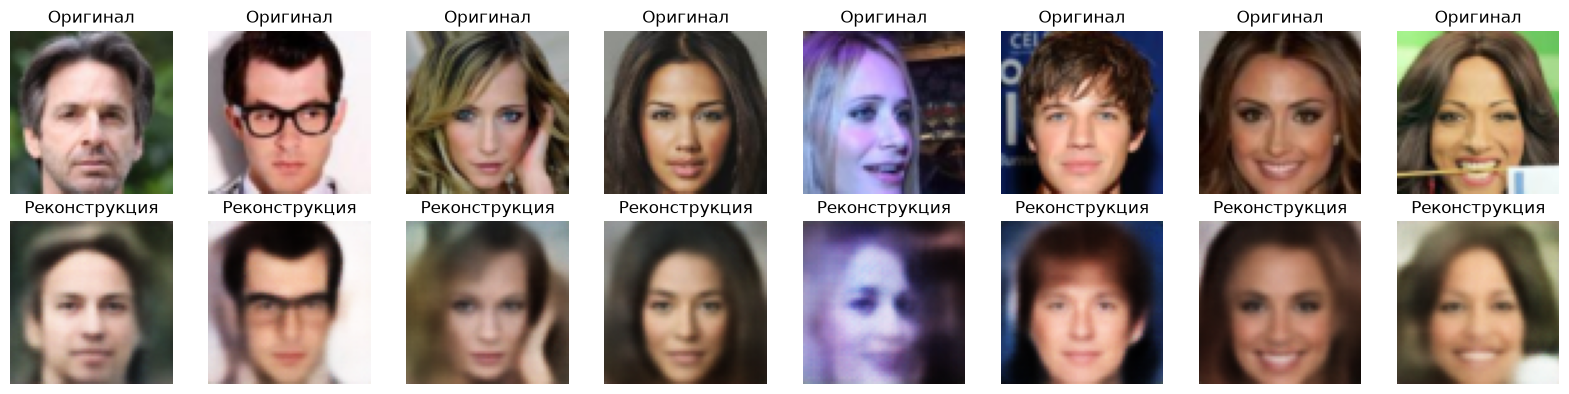

In [7]:
vae_model.eval()

x_batch, attrs_batch = next(iter(dataloader))
x_batch = x_batch.to(device)

with torch.no_grad():
    x_recon_batch, mu_batch, logvar_batch, z_batch = vae_model(x_batch)

x_vis = (x_batch * 0.5 + 0.5).clamp(0, 1).cpu()
x_recon_vis = (x_recon_batch * 0.5 + 0.5).clamp(0, 1).cpu()

num_show = 8
fig, axes = plt.subplots(2, num_show, figsize=(16, 4))
for i in range(num_show):
    axes[0, i].imshow(np.transpose(x_vis[i].numpy(), (1, 2, 0)))
    axes[0, i].axis('off')
    axes[0, i].set_title('Оригинал')
    axes[1, i].imshow(np.transpose(x_recon_vis[i].numpy(), (1, 2, 0)))
    axes[1, i].axis('off')
    axes[1, i].set_title('Реконструкция')
plt.tight_layout()
plt.show()

### Часть A. Шаг 6: Редактирование латентного пространства (улыбка → грусть)

Что сделать: использовать атрибут `Smiling` в CelebA для выделения улыбающихся и неулыбающихся лиц, вычислить направление в латентном пространстве и применить его к новым изображениям.

Средние по группам считаем по `mu`, а не по сэмплированному `z`: так в направление не попадает шум сэмплирования.

Ожидается: пары «до/после» с изменением эмоции, логирование результатов в TensorBoard.

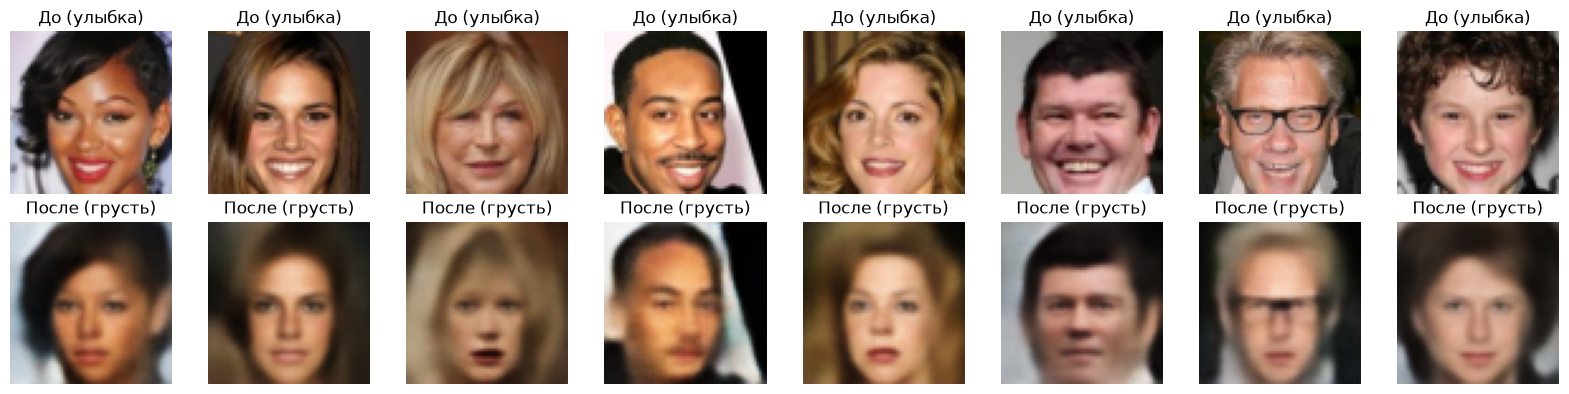

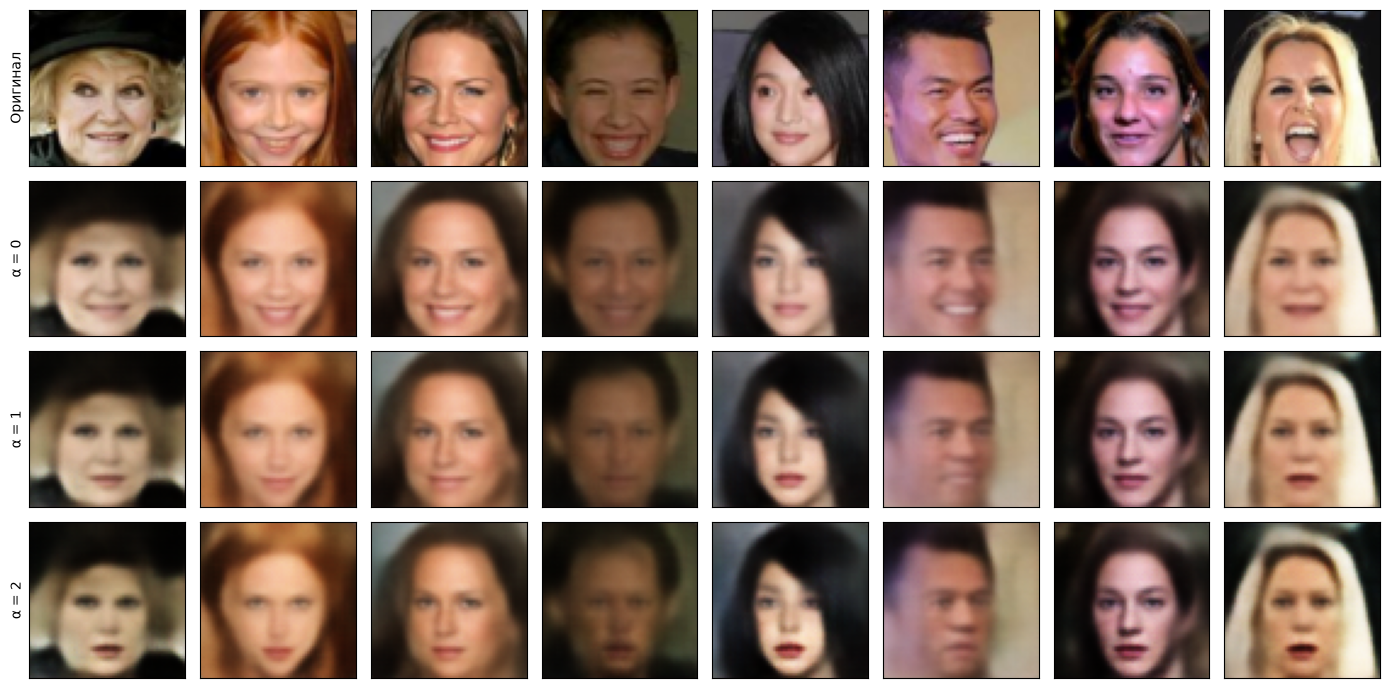

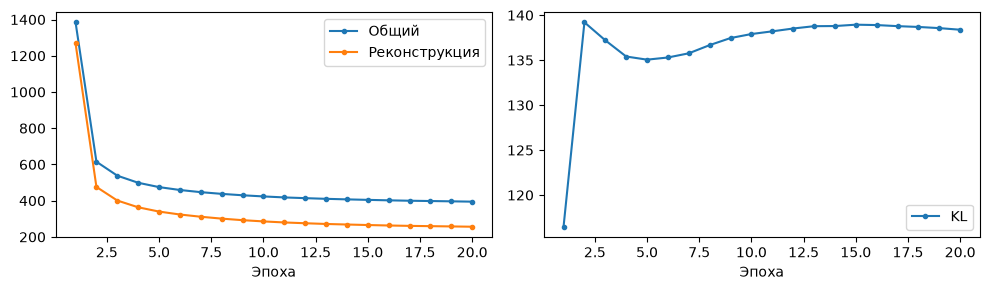

Редактирование эмоции выполнено и залогировано в TensorBoard.


In [8]:
attr_names = dataset.attr_names
smile_idx = attr_names.index('Smiling')

smile_mask = dataset.attr[:, smile_idx] == 1
sad_mask = dataset.attr[:, smile_idx] == 0  # атрибуты в CelebAWithAttrs — 0/1

smile_indices = torch.nonzero(smile_mask).squeeze().tolist()
sad_indices = torch.nonzero(sad_mask).squeeze().tolist()

N = 128
smile_indices = smile_indices[:N]
sad_indices = sad_indices[:N]

def get_batch_by_indices(indices):
    images = []
    for idx in indices:
        img, attr = dataset[idx]
        images.append(img)
    images = torch.stack(images, dim=0)
    return images.to(device)

vae_model.eval()
with torch.no_grad():
    smile_imgs = get_batch_by_indices(smile_indices)
    sad_imgs = get_batch_by_indices(sad_indices)

    _, smile_mu, smile_logvar, smile_z = vae_model(smile_imgs)
    _, sad_mu, sad_logvar, sad_z = vae_model(sad_imgs)

# Используем mu: среднее без шума сэмплирования
smile_z_mean = smile_mu.mean(dim=0)
sad_z_mean = sad_mu.mean(dim=0)

# YOUR CODE IS HERE
direction = sad_z_mean - smile_z_mean
alpha = 2.0
# Для демонстрации в исходной ячейке берём лица, не вошедшие в расчёт direction.
smile_indices = torch.where(smile_mask)[0][N:].tolist()

num_edit = 8
edit_indices = smile_indices[:num_edit]
edit_batch = get_batch_by_indices(edit_indices)

with torch.no_grad():
    _, edit_mu, edit_logvar, edit_z = vae_model(edit_batch)
    edited_z = edit_mu + alpha * direction
    edited_imgs = vae_model.decoder(edited_z)

edit_vis_orig = (edit_batch * 0.5 + 0.5).clamp(0, 1).cpu()
edit_vis_edited = (edited_imgs * 0.5 + 0.5).clamp(0, 1).cpu()

fig, axes = plt.subplots(2, num_edit, figsize=(16, 4))
for i in range(num_edit):
    axes[0, i].imshow(np.transpose(edit_vis_orig[i].numpy(), (1, 2, 0)))
    axes[0, i].axis('off')
    axes[0, i].set_title('До (улыбка)')
    axes[1, i].imshow(np.transpose(edit_vis_edited[i].numpy(), (1, 2, 0)))
    axes[1, i].axis('off')
    axes[1, i].set_title('После (грусть)')
plt.tight_layout()
plt.show()

# логгирование в Tensorboard
# YOUR CODE IS HERE
edit_grid = make_grid(torch.cat([edit_vis_orig, edit_vis_edited]), nrow=num_edit)
writer_vae.add_image('results/smile_edit', edit_grid, global_step)

with torch.no_grad():
    fixed_mu, _ = vae_model.encoder(fixed_vae)
    fixed_recon = vae_model.decoder(fixed_mu)
recon_examples = (torch.cat([fixed_vae, fixed_recon]) * 0.5 + 0.5).clamp(0, 1)
save_image(recon_examples, 'vae_reconstructions.png', nrow=8)

test_smile_indices = torch.where(eval_dataset.attr[:, smile_idx] == 1)[0][:num_edit]
test_smiles = torch.stack([eval_dataset[int(idx)][0] for idx in test_smile_indices]).to(device)
alphas = (0.0, 1.0, alpha)
with torch.no_grad():
    test_mu, _ = vae_model.encoder(test_smiles)
    test_edits = [vae_model.decoder(test_mu + strength * direction) for strength in alphas]

test_rows = torch.stack([test_smiles, *test_edits]).mul(0.5).add(0.5).clamp(0, 1).cpu()
test_grid = make_grid(test_rows.flatten(0, 1), nrow=num_edit)
writer_vae.add_image('results/test_smile_edit', test_grid, global_step)
fig_test, axes_test = plt.subplots(len(test_rows), num_edit, figsize=(14, 7))
row_labels = ['Оригинал', *[f'α = {strength:g}' for strength in alphas]]
for row, label in enumerate(row_labels):
    for col in range(num_edit):
        axes_test[row, col].imshow(test_rows[row, col].permute(1, 2, 0).numpy())
        axes_test[row, col].set_xticks([])
        axes_test[row, col].set_yticks([])
    axes_test[row, 0].set_ylabel(label)
fig_test.tight_layout()
fig_test.savefig('vae_smile_edit.png', dpi=150, bbox_inches='tight')
plt.show()

losses_vae = np.asarray(loss_history_vae)
fig_loss, (ax_main, ax_kl) = plt.subplots(1, 2, figsize=(10, 3))
epochs_vae = np.arange(1, len(losses_vae) + 1)
ax_main.plot(epochs_vae, losses_vae[:, 0], label='Общий', marker='.')
ax_main.plot(epochs_vae, losses_vae[:, 1], label='Реконструкция', marker='.')
ax_main.set_xlabel('Эпоха')
ax_main.legend()
ax_kl.plot(epochs_vae, losses_vae[:, 2], label='KL', marker='.')
ax_kl.set_xlabel('Эпоха')
ax_kl.legend()
fig_loss.tight_layout()
fig_loss.savefig('vae_loss.png', dpi=150, bbox_inches='tight')
plt.show()
writer_vae.close()

print('Редактирование эмоции выполнено и залогировано в TensorBoard.')

### Часть A. Шаг 7: Текстовое объяснение метода

Что сделать: кратко описать (1–2 абзаца), как вы вычисляли направление smile - sad и как изменение alpha влияет на результат.

Ожидается: понятное описание работы.

*Ваш ответ:*

Взяли по 128 фотографий из обучающей выборки с Smiling=1 и Smiling=0. Для каждой фотографии получили mu, среднее латентного распределения энкодера. Направление от улыбки к нейтральному выражению вычислили как разность средних mu группы без улыбки и группы с улыбкой. Для редактирования прибавили alpha таких векторов к mu нового лица и декодировали результат.

При alpha=0 получаем обычную реконструкцию. При положительном alpha усиливается сдвиг в сторону группы без улыбки. Сильный сдвиг может менять и другие особенности лица, поскольку направление получено из групповых различий. В CelebA Smiling=0 означает отсутствие улыбки, поэтому уменьшаем выраженность улыбки и оцениваем результат на отложенных лицах. На сохранённых примерах из тестовой выборки alpha=1 заметно ослабил улыбки, например во второй, третьей и шестой колонках. При alpha=2 сильнее меняются форма рта и некоторые другие черты лица.